<a href="https://colab.research.google.com/github/Bass-f/Mineria-de-Datos-Lab10/blob/main/Actividad_2_10_MineriadeDatos_LabClustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2.10 Laboratorio: Clustering y K-Means
**Asignatura:** Minería de Datos

**Nombre:** Bastián Fernández

# Ejercicio 1 · Clustering por partició

##1 - Hipótesis antes de calcular

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
[PosixPath('/kaggle/input/customer-segmentation-tutorial-in-python/Mall_Customers.csv')]


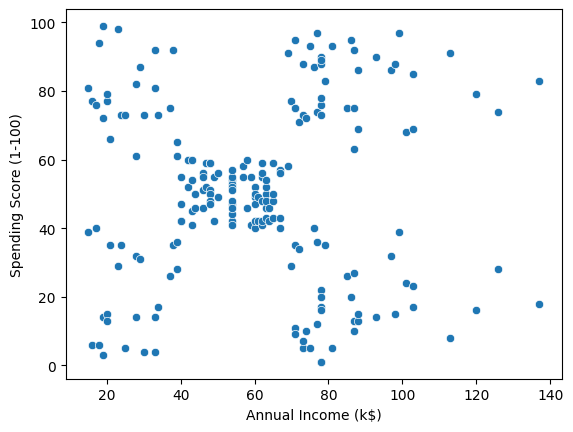

In [ ]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from google.colab import userdata
import kagglehub

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

ruta = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
print(list(pathlib.Path(ruta).iterdir()))

df = pd.read_csv(next(pathlib.Path(ruta).glob("*.csv")))

sns.scatterplot(data=df, x="Annual Income (k$)", y="Spending Score (1-100)")
plt.show()

##2 - Cargar y explorar

(200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.0

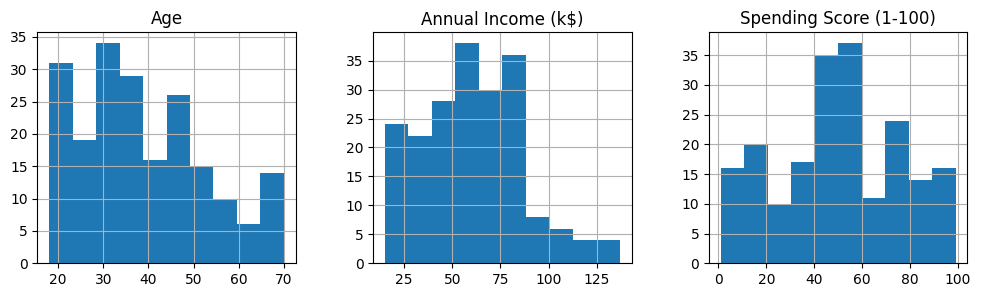

In [ ]:
print(df.shape)
df.info()
print(df.isna().sum())
print(df.describe())
print(df["Gender"].value_counts())

df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].hist(figsize=(12, 3), layout=(1, 3))
plt.show()

## 3 - Preparar: variables y escala sección

In [ ]:
cols = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[cols]
print(X.agg(["min", "max"]))

scaler = StandardScaler()
X_esc = pd.DataFrame(scaler.fit_transform(X), columns=cols)
print(X_esc.describe().round(2))   # media ~0, desviación ~1

     Annual Income (k$)  Spending Score (1-100)
min                  15                       1
max                 137                      99
       Annual Income (k$)  Spending Score (1-100)
count              200.00                  200.00
mean                -0.00                   -0.00
std                  1.00                    1.00
min                 -1.74                   -1.91
25%                 -0.73                   -0.60
50%                  0.04                   -0.01
75%                  0.67                    0.89
max                  2.92                    1.89


##4 - Ajustar K-means y explorar k

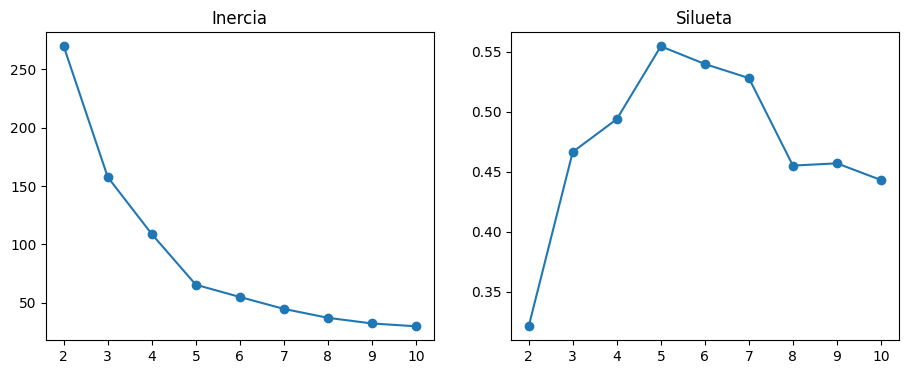

In [ ]:
ks = range(2, 11)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_esc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_esc, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inercias, "o-"); ax[0].set_title("Inercia")
ax[1].plot(ks, siluetas, "o-"); ax[1].set_title("Silueta")
plt.show()

##5 - Evaluar con más de una evidencia

In [ ]:
K = 5   # cámbialo según tu codo y tu silueta
ref = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_esc)

# Estabilidad: otras semillas vs. el ajuste de referencia
for s in range(5):
    lab = KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(X_esc)
    print("semilla", s, "ARI:", round(adjusted_rand_score(ref.labels_, lab), 3))

# Mini-experimento: sin estandarizar
lab_raw = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X)
print("ARI con vs sin estandarizar:", round(adjusted_rand_score(ref.labels_, lab_raw), 3))
print(pd.crosstab(ref.labels_, lab_raw))

semilla 0 ARI: 1.0
semilla 1 ARI: 0.985
semilla 2 ARI: 1.0
semilla 3 ARI: 0.985
semilla 4 ARI: 0.692
ARI con vs sin estandarizar: 1.0
col_0   0   1   2   3   4
row_0                    
0      81   0   0   0   0
1       0  39   0   0   0
2       0   0  22   0   0
3       0   0   0  35   0
4       0   0   0   0  23


##6 - Interpretar y decidir

          n  edad  ingreso  gasto
cluster                          
0        81  42.7     55.3   49.5
1        39  32.7     86.5   82.1
2        22  25.3     25.7   79.4
3        35  41.1     88.2   17.1
4        23  45.2     26.3   20.9


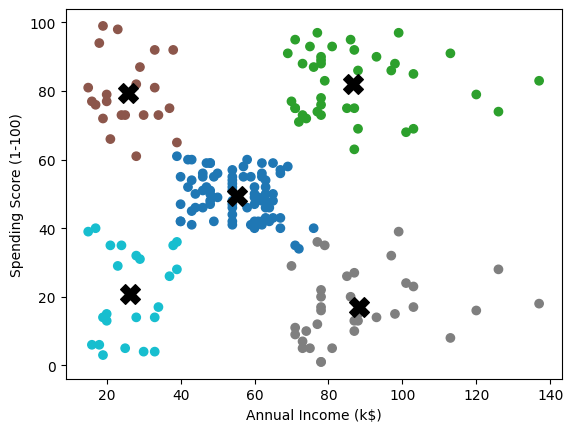

In [ ]:
df["cluster"] = ref.labels_

perfil = df.groupby("cluster").agg(
    n=("CustomerID", "count"),
    edad=("Age", "mean"),
    ingreso=("Annual Income (k$)", "mean"),
    gasto=("Spending Score (1-100)", "mean"),
).round(1)
print(perfil)

centros = scaler.inverse_transform(ref.cluster_centers_)   # a unidades originales

plt.scatter(df[cols[0]], df[cols[1]], c=df["cluster"], cmap="tab10")
plt.scatter(centros[:, 0], centros[:, 1], c="black", marker="X", s=200)
plt.xlabel(cols[0]); plt.ylabel(cols[1])
plt.show()

#Ejercicio 2 · Clustering jerárquico

## 1 - Hipótesis y muestra de trabajo

In [ ]:
import os, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from google.colab import userdata
import kagglehub

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

ruta = kagglehub.dataset_download("rohan0301/unsupervised-learning-on-country-data")
print(list(pathlib.Path(ruta).iterdir()))   # confirma el nombre del archivo

df = pd.read_csv(pathlib.Path(ruta) / "Country-data.csv")
print(sorted(df["country"].unique()))        # revisa cómo están escritos los nombres

# Criterio: Chile + países de América Latina + algunos de otras regiones como contraste
lista = ["Chile", "Argentina", "Brazil", "Uruguay", "Mexico", "Colombia", "Peru",
         "Ecuador", "Bolivia", "Paraguay", "Venezuela", "Costa Rica", "Panama",
         "Dominican Republic", "Guatemala", "Honduras", "El Salvador", "Jamaica",
         "Spain", "Portugal", "Italy", "Greece", "Poland", "Turkey", "South Korea",
         "China", "India", "United States", "Japan", "Germany", "South Africa", "Nigeria"]

print("No encontrados:", set(lista) - set(df["country"]))   # corrige si aparece alguno

sub = df[df["country"].isin(lista)].set_index("country")
print(sub.shape)

Using Colab cache for faster access to the 'unsupervised-learning-on-country-data' dataset.
[PosixPath('/kaggle/input/unsupervised-learning-on-country-data/Country-data.csv'), PosixPath('/kaggle/input/unsupervised-learning-on-country-data/data-dictionary.csv')]
['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chad', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia', 'Georgia'

## 2 - Cargar y explorar

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB
None
country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
       child_mort  exports  health  imports    income  inflation  life_expec  \
count       167.0    167.0   167.0    167.0     167.0      167.0       167.0   
me

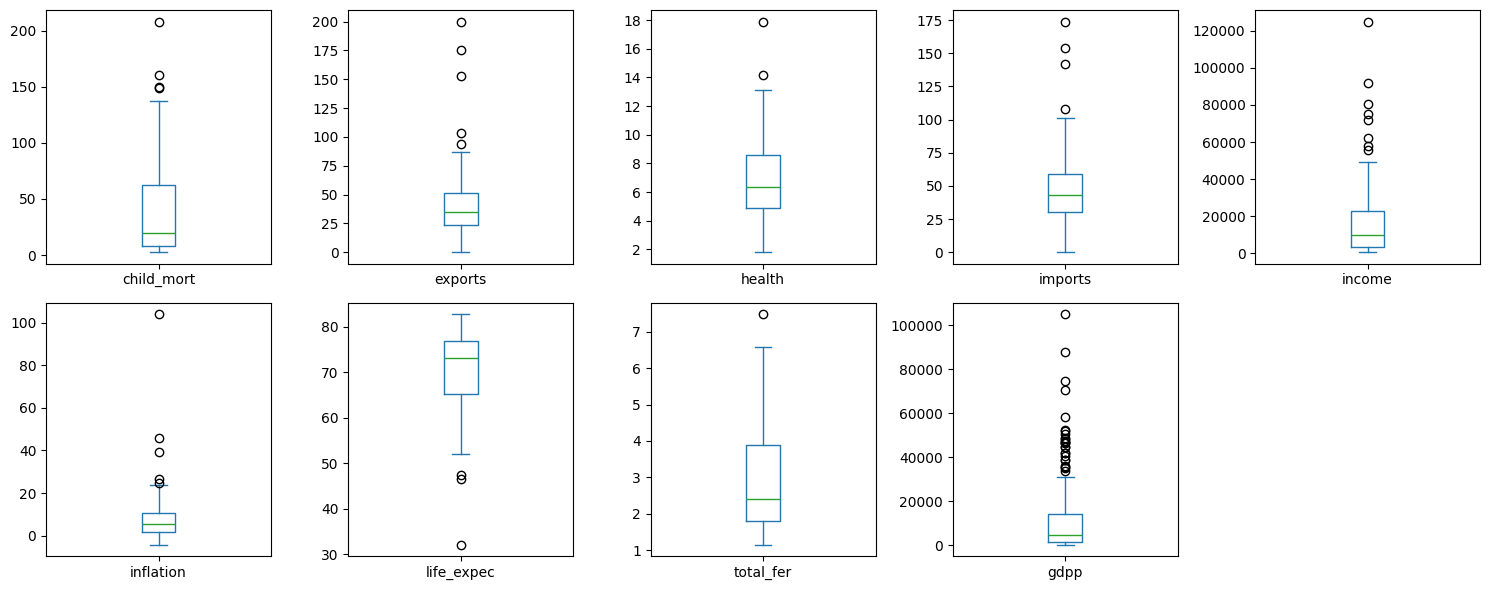

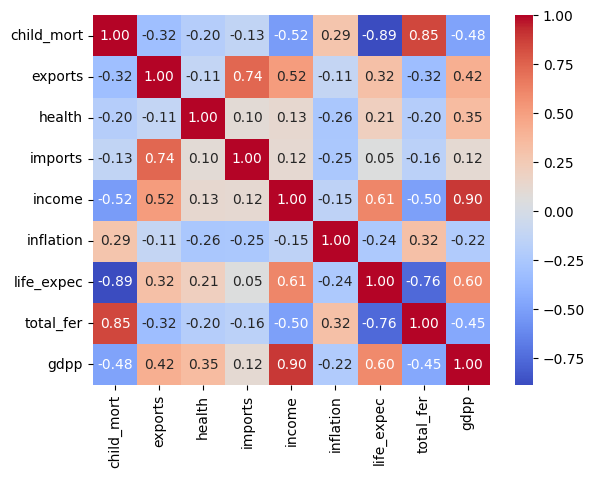

In [ ]:
print(df.info())
print(df.isna().sum())
print(df.describe().round(1))

df.drop(columns="country").plot(kind="box", subplots=True, layout=(2, 5), figsize=(15, 6))
plt.tight_layout(); plt.show()

sns.heatmap(df.drop(columns="country").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

## 3 - Preparar: ¿cuánto pesa cada variable?

In [ ]:
X_raw = sub.copy()
X_esc = pd.DataFrame(StandardScaler().fit_transform(sub), index=sub.index, columns=sub.columns)
etiquetas = list(sub.index)

print("Forma:", X_raw.shape, "|", X_esc.shape)

print("\nRango de cada variable (original):")
print(X_raw.agg(["min", "max"]).T)

print("\nMedia y desviación tras estandarizar:")
print(X_esc.agg(["mean", "std"]).T.round(2))

print("\nPrimeros países:")
print(X_esc.head())

Forma: (30, 11) | (30, 11)

Rango de cada variable (original):
                min       max
child_mort     3.20    130.00
exports       10.70     70.00
health         4.05     17.90
imports       11.80     78.20
income      4410.00  49400.00
inflation     -1.90    104.00
life_expec    54.30     82.80
total_fer      1.23      5.84
gdpp        1350.00  48400.00
cluster_h      1.00      4.00
cluster_km     0.00      3.00

Media y desviación tras estandarizar:
            mean   std
child_mort  -0.0  1.02
exports      0.0  1.02
health      -0.0  1.02
imports      0.0  1.02
income       0.0  1.02
inflation   -0.0  1.02
life_expec  -0.0  1.02
total_fer   -0.0  1.02
gdpp        -0.0  1.02
cluster_h   -0.0  1.02
cluster_km  -0.0  1.02

Primeros países:
           child_mort   exports    health   imports    income  inflation  \
country                                                                    
Argentina   -0.303214 -0.849206  0.070556 -1.112884  0.054040   0.572488   
Bolivia      0.9

##4 - Construir la jerarquía y leer el dendrograma

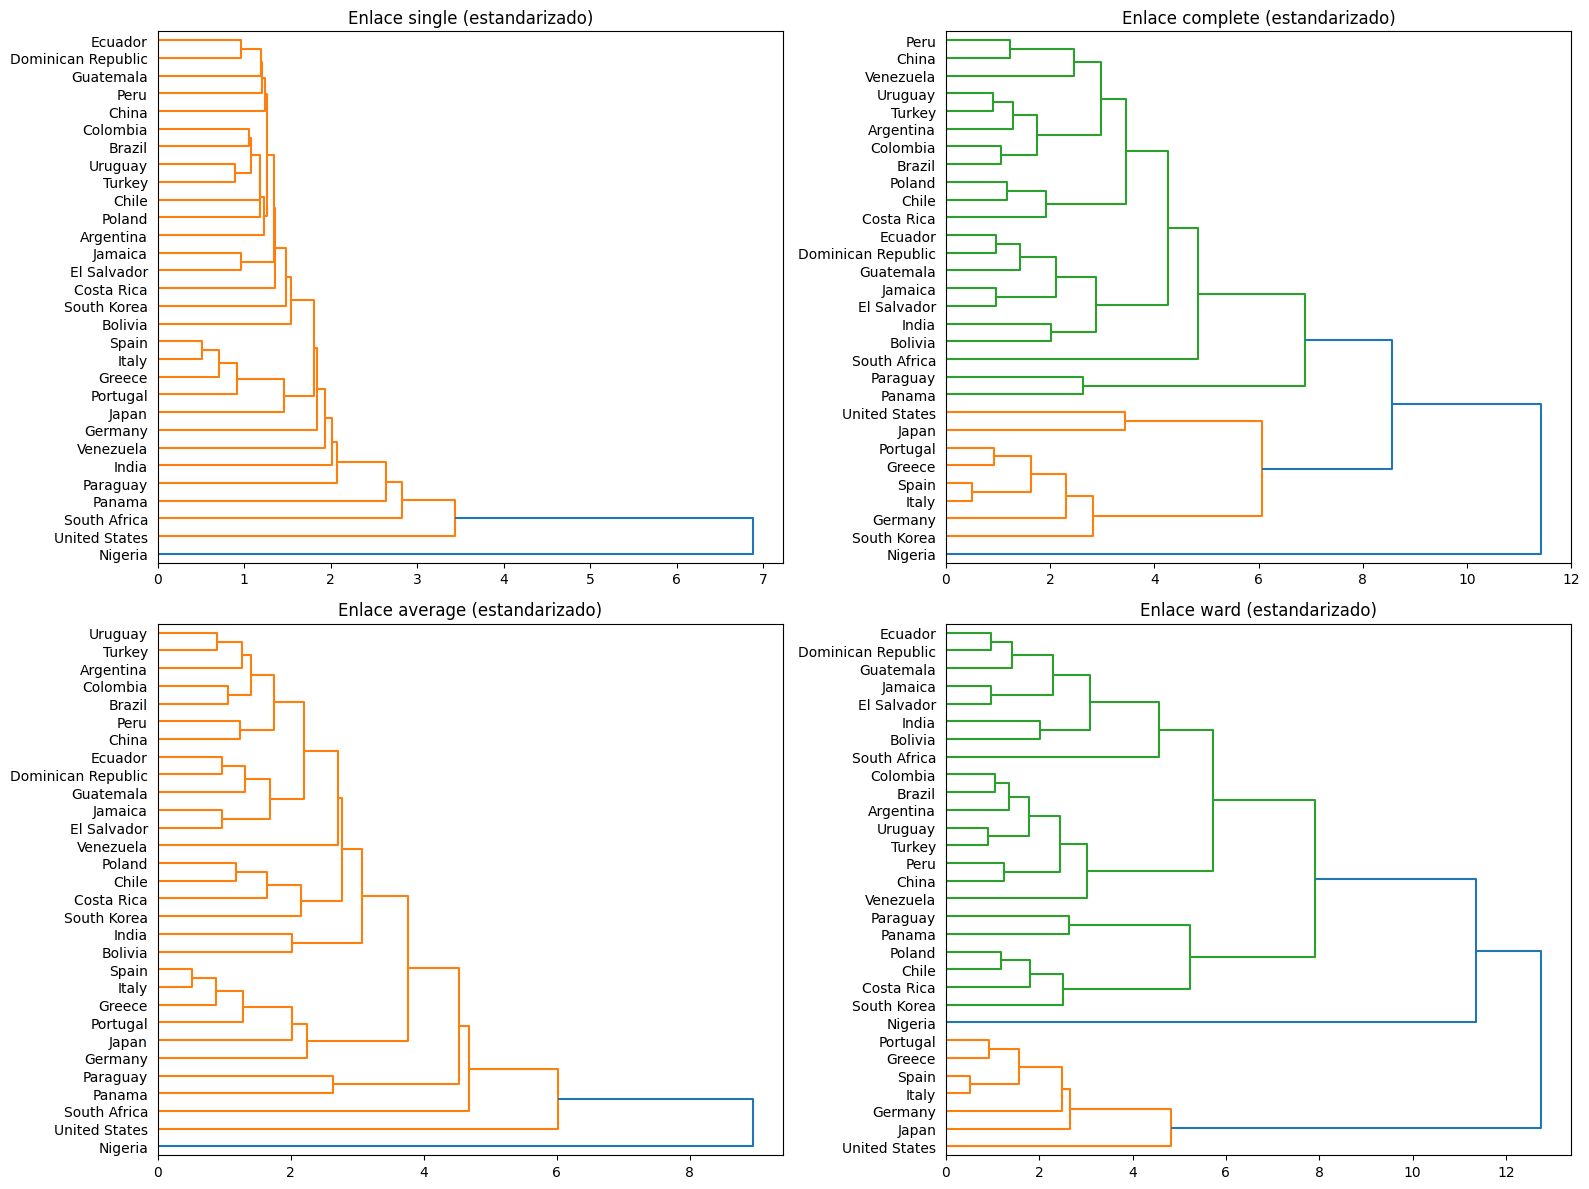

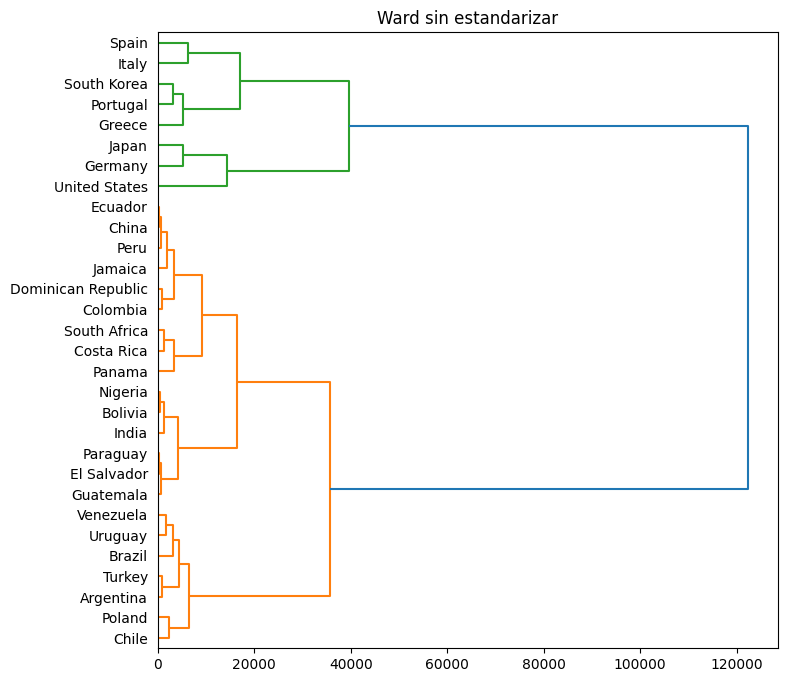

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, metodo in zip(axes.flat, ["single", "complete", "average", "ward"]):
    Z = linkage(X_esc, method=metodo)
    dendrogram(Z, labels=etiquetas, orientation="right", ax=ax)
    ax.set_title(f"Enlace {metodo} (estandarizado)")
plt.tight_layout(); plt.show()

# Mismo enlace (ward) sin estandarizar
plt.figure(figsize=(8, 8))
dendrogram(linkage(X_raw, method="ward"), labels=etiquetas, orientation="right")
plt.title("Ward sin estandarizar"); plt.show()

##5 - Cortar la jerarquía

Últimas alturas de fusión: [ 4.82  5.24  5.73  7.92 11.36 12.76]
2 grupos | silueta: 0.317 | tamaños: [ 7 23]
3 grupos | silueta: 0.348 | tamaños: [ 7 22  1]
4 grupos | silueta: 0.292 | tamaños: [ 7  6 16  1]
5 grupos | silueta: 0.235 | tamaños: [7 6 8 8 1]
Cofenética: 0.576


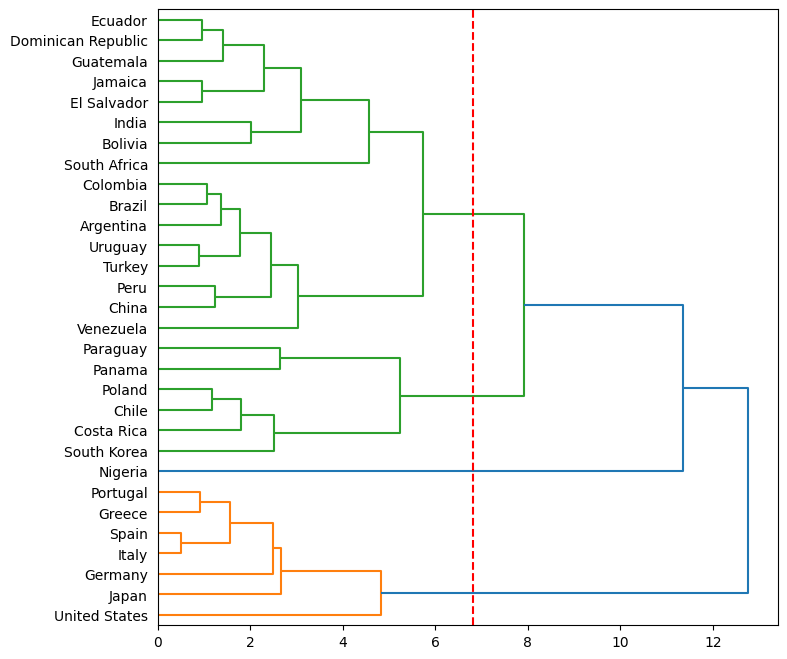

In [ ]:
Z = linkage(X_esc, method="ward")      # el enlace que elijas
print("Últimas alturas de fusión:", Z[-6:, 2].round(2))

for k in [2, 3, 4, 5]:
    lab = fcluster(Z, k, criterion="maxclust")
    print(k, "grupos | silueta:", round(silhouette_score(X_esc, lab), 3), "| tamaños:", np.bincount(lab)[1:])

c, _ = cophenet(Z, pdist(X_esc))
print("Cofenética:", round(c, 3))

K = 4   # el corte que elijas
corte = (Z[-K, 2] + Z[-(K - 1), 2]) / 2
plt.figure(figsize=(8, 8))
dendrogram(Z, labels=etiquetas, orientation="right")
plt.axvline(corte, color="red", linestyle="--")   # con orientation="right" la altura va en el eje x
plt.show()

##6 - Interpretar y comparar con K-means

In [ ]:
sub["cluster_h"] = fcluster(Z, K, criterion="maxclust")

for g, paises in sub.groupby("cluster_h").groups.items():
    print(f"Grupo {g}:", list(paises))

print(sub.groupby("cluster_h").mean().round(1))
print("Chile está en el grupo", sub.loc["Chile", "cluster_h"])

# K-means con el mismo K sobre la matriz estandarizada
sub["cluster_km"] = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_esc)

print(pd.crosstab(sub["cluster_h"], sub["cluster_km"]))
print("ARI:", round(adjusted_rand_score(sub["cluster_h"], sub["cluster_km"]), 3))

Grupo 1: ['Germany', 'Greece', 'Italy', 'Japan', 'Portugal', 'Spain', 'United States']
Grupo 2: ['Chile', 'Costa Rica', 'Panama', 'Paraguay', 'Poland', 'South Korea']
Grupo 3: ['Argentina', 'Bolivia', 'Brazil', 'China', 'Colombia', 'Dominican Republic', 'Ecuador', 'El Salvador', 'Guatemala', 'India', 'Jamaica', 'Peru', 'South Africa', 'Turkey', 'Uruguay', 'Venezuela']
Grupo 4: ['Nigeria']
           child_mort  exports  health  imports   income  inflation  \
cluster_h                                                             
1                 4.3     24.6    11.3     26.9  35742.9        0.3   
2                12.1     47.6     7.9     47.4  17881.7        4.8   
3                26.7     25.1     6.6     28.0  11216.9        9.9   
4               130.0     25.3     5.1     17.4   5150.0      104.0   

           life_expec  total_fer     gdpp  
cluster_h                                  
1                80.8        1.5  35800.0  
2                78.0        2.0  11185.0  
3    